# Capstone Two: Data Wrangling  
## Understanding Hospital Readmissions for Patients With Diabetes

Kirti Sharma

This notebook covers the data wrangling step for my second capstone project.

My project focuses on understanding which patient and hospital-related factors are associated with readmission within 30 days for patients with diabetes.

The dataset is the Diabetes 130-US Hospitals for Years 1999–2008 dataset from the UCI Machine Learning Repository.

For this step, I will:
- load and review the data;
- check column names and data types;
- identify missing values;
- check duplicates;
- review numeric values for possible outliers;
- create a simple 30-day readmission target;
- save a cleaned dataset for the next phase of the project.


## 1. Import Libraries

I will use pandas and NumPy for data wrangling and matplotlib for a few simple visual checks.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 2. Load the Data

I downloaded `diabetic_data.csv` from the UCI Machine Learning Repository and placed it in the same folder as this notebook.


In [2]:
df = pd.read_csv("diabetic_data.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


## 3. Review the Data

Before cleaning the data, I want to understand its structure, column names, and data types.


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

In [4]:
print(df.columns.tolist())

['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']


In [5]:
df.describe()

,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,1.017660e+05,1.017660e+05,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,1.652016e+08,5.433040e+07,2.024006,3.715642,5.754437,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,1.026403e+08,3.869636e+07,1.445403,5.280166,4.064081,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.252200e+04,1.350000e+02,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,8.496119e+07,2.341322e+07,1.000000,1.000000,1.000000,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,1.523890e+08,4.550514e+07,1.000000,1.000000,7.000000,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,2.302709e+08,8.754595e+07,3.000000,4.000000,7.000000,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,4.438672e+08,1.895026e+08,8.000000,28.000000,25.000000,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


In [6]:
# Number of unique values in each column
df.nunique().sort_values()

citoglipton                      1
examide                          1
troglitazone                     2
change                           2
metformin-pioglitazone           2
metformin-rosiglitazone          2
glimepiride-pioglitazone         2
glipizide-metformin              2
acetohexamide                    2
tolbutamide                      2
diabetesMed                      2
A1Cresult                        3
max_glu_serum                    3
readmitted                       3
tolazamide                       3
gender                           3
acarbose                         4
rosiglitazone                    4
pioglitazone                     4
glyburide                        4
glipizide                        4
insulin                          4
glimepiride                      4
glyburide-metformin              4
miglitol                         4
chlorpropamide                   4
metformin                        4
repaglinide                      4
nateglinide         

In [7]:
# Review data types and unique values

column_summary = pd.DataFrame({
    "data_type": df.dtypes,
    "unique_count": df.nunique(),
    "unique_percent": (df.nunique() / len(df)) * 100
})

column_summary

,data_type,unique_count,unique_percent
encounter_id,int64,101766,100.000000
patient_nbr,int64,71518,70.276910
race,object,6,0.005896
gender,object,3,0.002948
age,object,10,0.009826
weight,object,10,0.009826
admission_type_id,int64,8,0.007861
discharge_disposition_id,int64,26,0.025549
admission_source_id,int64,17,0.016705
time_in_hospital,int64,14,0.013757


### Initial observations

This summary helps me understand the type of each variable and how much variation exists in each column. Identifier columns such as `encounter_id` have many unique values, while some medication columns contain only a few categories.

The dataset contains both numeric and categorical variables. Some columns use codes or categories instead of continuous numbers. The target column, `readmitted`, contains the original readmission categories.

The next step is to inspect missing values and other data-quality issues.


## 4. Missing Values

The dataset uses `?` in some columns to represent missing information. I will replace `?` with `NaN` so pandas recognizes these values as missing.


In [8]:
# Replace the question mark missing-value marker with NaN
df = df.replace("?", np.nan)

# Check total missing values by column
df.isnull().sum().sort_values(ascending=False)

weight                      98569
max_glu_serum               96420
A1Cresult                   84748
medical_specialty           49949
payer_code                  40256
race                         2273
diag_3                       1423
diag_2                        358
diag_1                         21
encounter_id                    0
troglitazone                    0
tolbutamide                     0
pioglitazone                    0
rosiglitazone                   0
acarbose                        0
miglitol                        0
citoglipton                     0
tolazamide                      0
examide                         0
glipizide                       0
insulin                         0
glyburide-metformin             0
glipizide-metformin             0
glimepiride-pioglitazone        0
metformin-rosiglitazone         0
metformin-pioglitazone          0
change                          0
diabetesMed                     0
glyburide                       0
repaglinide   

In [9]:
# Calculate missing-value percentages
missing_percent = (df.isnull().sum() / len(df) * 100).sort_values(ascending=False)

missing_percent[missing_percent > 0]

weight               96.858479
max_glu_serum        94.746772
A1Cresult            83.277322
medical_specialty    49.082208
payer_code           39.557416
race                  2.233555
diag_3                1.398306
diag_2                0.351787
diag_1                0.020636
dtype: float64

### Missing-value decision

I will remove columns that are more than 90% missing because there is not enough information in those columns to use them reliably.

For the remaining categorical columns, I will use `"Unknown"` for missing values instead of removing the entire hospital encounter.


In [10]:
# Identify columns with more than 90% missing values
columns_to_drop = missing_percent[missing_percent > 90].index.tolist()

print("Columns with more than 90% missing values:", columns_to_drop)

df = df.drop(columns=columns_to_drop, errors="ignore")

print("New dataset shape:", df.shape)

Columns with more than 90% missing values: ['weight', 'max_glu_serum']
New dataset shape: (101766, 48)


In [11]:
# Fill remaining missing categorical values with "Unknown"
categorical_columns = df.select_dtypes(include="object").columns

df[categorical_columns] = df[categorical_columns].fillna("Unknown")

# Check whether missing values remain
df.isnull().sum().sort_values(ascending=False).head(10)

encounter_id     0
patient_nbr      0
glimepiride      0
acetohexamide    0
glipizide        0
glyburide        0
tolbutamide      0
pioglitazone     0
rosiglitazone    0
acarbose         0
dtype: int64

## 5. Check for Duplicates

I will check for exact duplicate rows and duplicate encounter IDs.

A repeated `patient_nbr` does not automatically mean the row is a duplicate, because the same patient may have more than one hospital encounter.


In [12]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate encounter IDs:", df["encounter_id"].duplicated().sum())
print("Repeated patient numbers:", df["patient_nbr"].duplicated().sum())

Exact duplicate rows: 0
Duplicate encounter IDs: 0
Repeated patient numbers: 30248


In [13]:
# Remove exact duplicate rows, if there are any
df = df.drop_duplicates()

print("Dataset shape after duplicate check:", df.shape)

Dataset shape after duplicate check: (101766, 48)


### Duplicate decision

I only remove exact duplicate rows.

I keep repeated patient numbers because one patient may have multiple valid hospital encounters. Removing repeated patients at this stage could remove useful information about readmission patterns.


## 6. Review Numeric Values and Possible Outliers

I will review the main numeric variables using summary statistics. I am not automatically deleting extreme values because high numbers of hospital visits, medications, procedures, or laboratory tests may be real and important for this project.


In [14]:
numeric_columns = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]

df[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
time_in_hospital,101766.0,4.395987,2.985108,1.0,2.0,4.0,6.0,14.0
num_lab_procedures,101766.0,43.095641,19.674362,1.0,31.0,44.0,57.0,132.0
num_procedures,101766.0,1.339730,1.705807,0.0,0.0,1.0,2.0,6.0
num_medications,101766.0,16.021844,8.127566,1.0,10.0,15.0,20.0,81.0
number_outpatient,101766.0,0.369357,1.267265,0.0,0.0,0.0,0.0,42.0
number_emergency,101766.0,0.197836,0.930472,0.0,0.0,0.0,0.0,76.0
number_inpatient,101766.0,0.635566,1.262863,0.0,0.0,0.0,1.0,21.0
number_diagnoses,101766.0,7.422607,1.933600,1.0,6.0,8.0,9.0,16.0


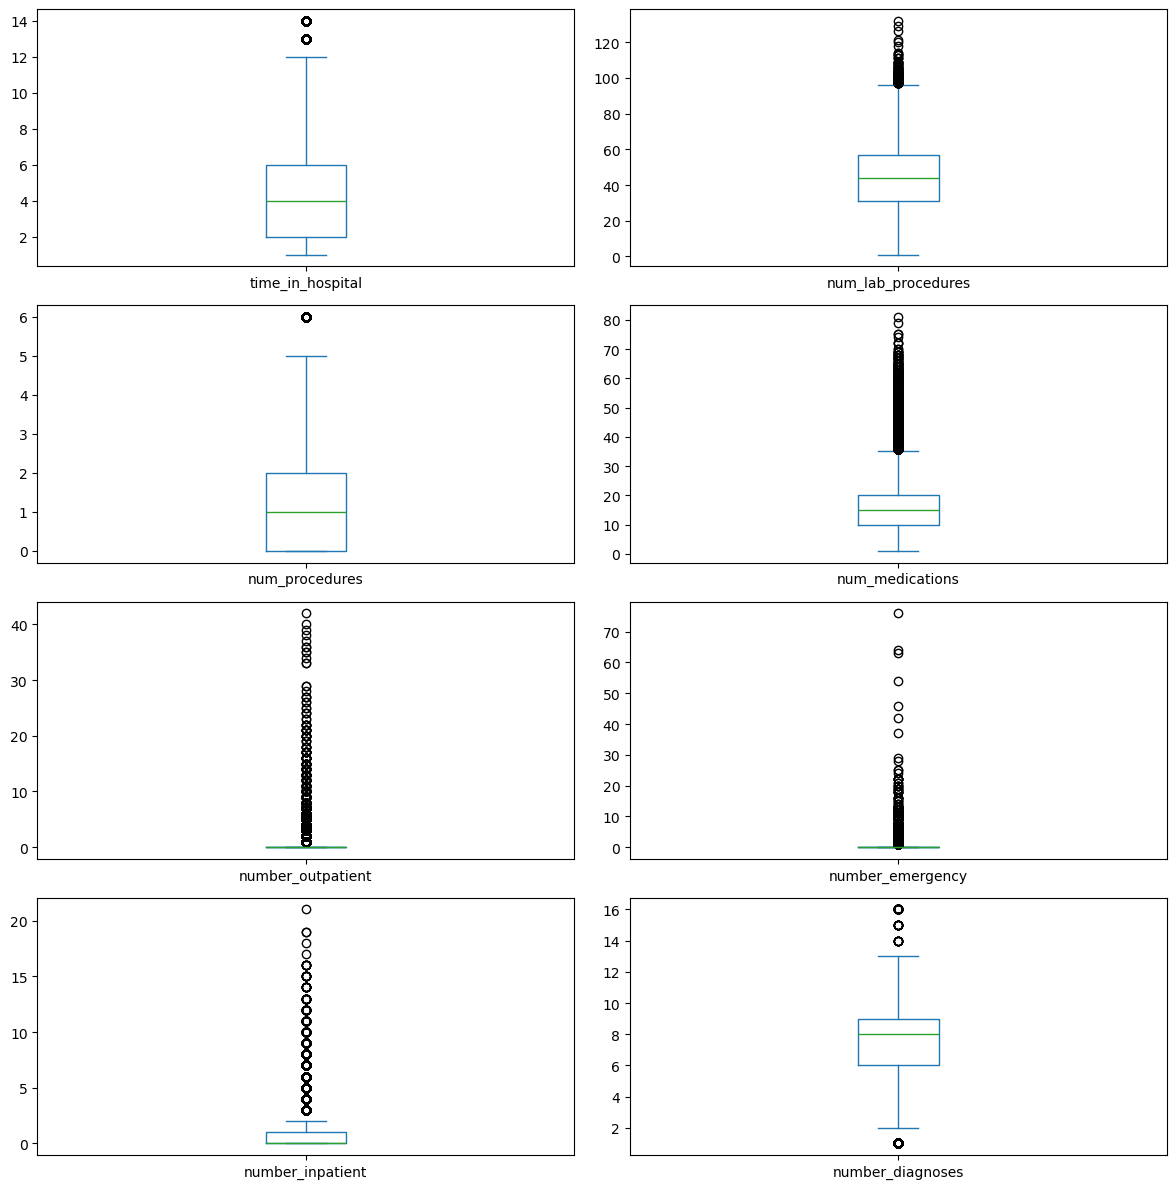

In [15]:
# Simple boxplots to visually review possible outliers
df[numeric_columns].plot(
    kind="box",
    subplots=True,
    layout=(4, 2),
    figsize=(12, 12),
    sharex=False,
    sharey=False
)

plt.tight_layout()
plt.show()

### Outlier decision

The boxplots may show extreme values in some of the hospital-use variables. I will keep these values unless there is evidence that they are impossible or entered incorrectly.

For this healthcare dataset, an unusually high number of visits or medications could represent a patient with more complex healthcare needs and may be relevant to readmission.


## 7. Check Basic Data Ranges

I will perform a few simple checks for values that would not make sense, such as negative counts.


In [16]:
for column in numeric_columns:
    negative_count = (df[column] < 0).sum()
    print(column, "negative values:", negative_count)

time_in_hospital negative values: 0
num_lab_procedures negative values: 0
num_procedures negative values: 0
num_medications negative values: 0
number_outpatient negative values: 0
number_emergency negative values: 0
number_inpatient negative values: 0
number_diagnoses negative values: 0


In [17]:
# Review the hospital stay range
print("Minimum hospital stay:", df["time_in_hospital"].min())
print("Maximum hospital stay:", df["time_in_hospital"].max())

# Review the readmission categories
print("\nReadmission categories:")
print(df["readmitted"].value_counts())

Minimum hospital stay: 1
Maximum hospital stay: 14

Readmission categories:
readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64


## 8. Create the 30-Day Readmission Target

The original `readmitted` column contains:

- `<30` = readmitted within 30 days;
- `>30` = readmitted after 30 days;
- `NO` = no recorded readmission.

Because my project focuses specifically on readmission within 30 days, I will create a binary target:

- `1` = readmitted within 30 days;
- `0` = not readmitted within 30 days.


In [18]:
df["readmitted_30"] = np.where(df["readmitted"] == "<30", 1, 0)

df["readmitted_30"].value_counts()

readmitted_30
0    90409
1    11357
Name: count, dtype: int64

The original `readmitted` column is kept for reference during data wrangling, but it will not be used as a predictor when modeling because readmitted_30 is created directly from it.

In [19]:
# Percentage of encounters readmitted within 30 days
df["readmitted_30"].value_counts(normalize=True) * 100

readmitted_30
0    88.840084
1    11.159916
Name: proportion, dtype: float64

## 9. Final Review

Before saving the cleaned data, I will do one final check of the dataset.


In [20]:
print("Final shape:", df.shape)
print("Exact duplicate rows:", df.duplicated().sum())
print("Total missing values:", df.isnull().sum().sum())

df.head()

Final shape: (101766, 49)
Exact duplicate rows: 0
Total missing values: 0


,encounter_id,patient_nbr,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,...,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted,readmitted_30
0,2278392,8222157,Caucasian,Female,[0-10),6,25,1,1,Unknown,...,No,No,No,No,No,No,No,No,NO,0
1,149190,55629189,Caucasian,Female,[10-20),1,1,7,3,Unknown,...,Up,No,No,No,No,No,Ch,Yes,>30,0
2,64410,86047875,AfricanAmerican,Female,[20-30),1,1,7,2,Unknown,...,No,No,No,No,No,No,No,Yes,NO,0
3,500364,82442376,Caucasian,Male,[30-40),1,1,7,2,Unknown,...,Up,No,No,No,No,No,Ch,Yes,NO,0
4,16680,42519267,Caucasian,Male,[40-50),1,1,7,1,Unknown,...,Steady,No,No,No,No,No,Ch,Yes,NO,0


## 10. Save the Cleaned Dataset

The cleaned file will be used later for exploratory data analysis, preprocessing, and modeling.


In [21]:
df.to_csv("diabetes_readmission_clean.csv", index=False)

print("Cleaned dataset saved as diabetes_readmission_clean.csv")

Cleaned dataset saved as diabetes_readmission_clean.csv


## Data Wrangling Summary

The main cleaning steps I completed were:

1. Loaded and reviewed the UCI diabetes hospital dataset.
2. Checked column names, data types, summary statistics, and unique values.
3. Replaced `?` with `NaN`.
4. Calculated missing-value counts and percentages.
5. Removed columns with more than 90% missing data.
6. Filled remaining missing categorical values with `Unknown`.
7. Checked exact duplicate rows and duplicate encounter IDs.
8. Kept repeated patients because a patient may have more than one valid hospital encounter.
9. Reviewed numeric ranges and possible outliers.
10. Kept plausible extreme values because they may contain useful information about hospital utilization.
11. Created a binary `readmitted_30` target for the project.
12. Saved the cleaned dataset for the next capstone step.
